# Código para revisión de proteínas usando RCSB PDB Search API

**Por: Barrientos González Diana, Contreras Rivera Jair Emiliano & González Lopez Leonardo Daniel**

Primero, cargamos librerías necesarias para la consulta.

Se utilizó la base de datos RCSB PDB, dispoiinble en: https://search.rcsb.org/index.html#building-search-request

## Parte 1. Consulta de estructuras en el PDB
Realiza una búsqueda de las estructuras correspondientes a la familia de proteínas asignada a tu equipo.
Puedes utilizar directamente la PDB REST API mediante solicitudes POST con parámetros en formato JSON, o
utilizar pypdb como alternativa.
Desarrolla un script que permita recuperar los identificadores de las estructuras que cumplen con tu criterio de
búsqueda. Documenta brevemente cómo definiste la consulta y qué consideraste como una estructura
perteneciente a tu familia.

**¿Cómo definimos la consulta y qué consideremos como una estructura?**

La consulta de la familia la definimos como una búsqueda de las palabras **pectate lyase** en manera de *full text*, lo que significa que va a buscar diferentes atributos de texto como anotaciones asociadas a estructuras de PDB o definiciones moleculares, no solamente consideraba que el nombre de la estructura se llamara *pectate lyase*.

In [ ]:
#Sirve para madnar peticiones HTTP  a serivdores como PDB:)
library(httr2)

#Sirve para pasar de formatos de R a json, formatos que usan la mayoria de bases de datos
library(jsonlite)

In [ ]:
#Cargamos el URL por default de PDB. Todas las consultas se mandan a trvés de este
url <- "https://search.rcsb.org/rcsbsearch/v2/query"

# Dentro de este vamos a definir la busqueda de nuestra familia, en este caso la familia de las pextato liasas
#Vamos a recoger con full text todas aquellas que tengan reportada esta palabra
familia <- list(
  type = "terminal",
  service = "full_text",
  parameters = list(value = "\"pectate lyase\""))

# Vamos a usar como query la familia previamente dfeinida. Adicionalmetne, vamos a retornar las entradas de PDB y devolver las entradas del 0 al 100
query <- list(
  query = familia,
  return_type = "entry",
  request_options = list(paginate = list(start = 0, rows = 100)))

#Vamos a mandar toda la peticion. reques() crea la peticion HTTP, req_body_json(() adjunta la lista como formato json y finalmente req_perform() la adjunta
response <- request(url) |> req_body_json(query) |> req_perform()

#Esta funcion convierte el json en una lista de R
data <- resp_body_json(response)

# Mostramos el total de estructuras identificadas
if (!is.null(data$total_count)) {
  cat("Total de estructuras encontradas:", data$total_count, "\n")
} else {
  cat("No se encontraron estructuras para esta consulta.\n")
}

Total de estructuras encontradas: 413 


## Parte 2. Exploración de los registros

A partir de los resultados de la búsqueda, recupera y analiza la información necesaria para responder los
siguientes puntos. Incluye una gráfica adecuada para comunicar cada distribución o comparación.

### 1. ¿Cuántas estructuras de la familia identificaste en el PDB?

In [ ]:
# Extraemos los identificadores del objeto 'data' obtenido en el paso anterior
pdb_ids <- sapply(data$result_set, function(x) x$identifier)

# Ahora podemos conocer la longitud y ver los primeros elementos
length(pdb_ids)
head(pdb_ids, 10)

[1] 100

[1] "1PE9" "1BN8" "1OOC" "1O88" "1EE6" "2PEC" "1PCL" "1PLU" "1JRG" "1O8D"

### 2. ¿Cómo se distribuyen las estructuras de acuerdo con el método experimental utilizado? Reporta los métodos identificados y la frecuencia de cada uno.

In [ ]:
#imprime el total de estructuras relacionadas ala fmailia
data$total_count
names(data)

[1] 413

[1] "query_id"    "result_type" "total_count" "result_set"

In [ ]:
#query ayuda a realizar búsquedas en distintos campos, en el campo de familia encontrado arriba
query <- list(query = familia, return_type = "entry", request_options = list(return_all_hits = TRUE))
# la consulta será con el url, tomando en cuenta mi tipo de búsqueda y ejecuta
response <- request(url) |> req_body_json(query) |> req_perform()
#convierte la respuesta de JSON en algo usable para R
data <- resp_body_json(response)
#devuelve los IDs de cada entrada de PDB
pdb_ids <- sapply(data$result_set, function(x) x$identifier)
#url a usar
url_graphql <- "https://data.rcsb.org/graphql"
#va a ayudar a concatenar los metodos encontrados en un vector q inicia vacío
metodos_todos <- c()
#divide los IDs en grupos de 100
for (grupo in split(pdb_ids, ceiling(seq_along(pdb_ids) / 100))) {
  #da formato a mis IDs
  ids_txt <- paste0('"', grupo, '"', collapse = ",")
  #por cada entrada de if pon el metodo
  q <- paste0("{ entries(entry_ids: [", ids_txt, "]) { exptl { method } } }")
  #encuentra los IDs y recupera datos de cada uno
  resp <- request(url_graphql) |> req_body_json(list(query = q)) |> req_perform()
  #manda la consulta de mi lista a una variable
  d <- resp_body_json(resp)$data$entries
  #convierte la respuesta a lista y se queda solo con entries
  #trae un elemento, cada uno con su campo exptl
  for (e in d) {
    metodos_todos <- c(metodos_todos, unique(sapply(e$exptl, function(m) m$method)))}}
#presentalo como data frame en una tabla
metodos <- as.data.frame(table(metodos_todos))
names(metodos) <- c("metodo", "frecuencia")
metodos


metodo,frecuencia
<fct>,<int>
ELECTRON MICROSCOPY,51
SOLUTION NMR,6
X-RAY DIFFRACTION,356


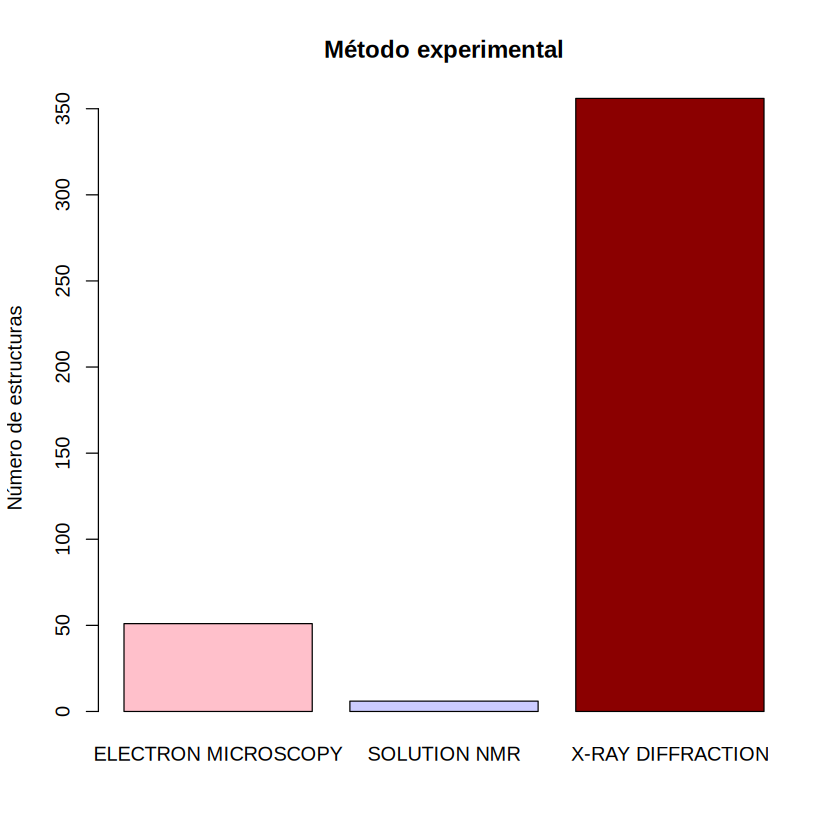

In [ ]:
#imprime un barplot de la tabla de arriba
barplot(metodos$frecuencia, names.arg = metodos$metodo,ylab = "Número de estructuras", main = "Método experimental", col = c("Pink", "#CCCCFF", "#8B0000"))

## 3. ¿Qué organismos están representados en los registros? Presenta los organismos más frecuentes y el número de estructuras asociado a cada uno.

In [ ]:
query <- list(#query realiza la búsqueda q le solicito
  query = familia,#de mi familia de interés
  return_type = "entry",
  request_options = list(#configura como quiero mi reusltado
    paginate = list(start = 0, rows = 0),#no quiero la lista, solo los conteos
    facets = list(list(
      name = "Organismo",#es la etiqueta q le asigno al atributo q le pido
      aggregation_type = "terms",
      attribute = "rcsb_entity_source_organism.ncbi_scientific_name"#el nombre científico de acda organismo
    ))
  )
)
#la consulta será con el url, tomando en cuenta mi tipo de búsqueda y ejecuta
response <- request(url) |> req_body_json(query) |> req_perform()
#convierte la respuesta de JSON en algo usable para R
data <- resp_body_json(response)

#agrupa por valores distintos del atributo: una cubeta (bucket) por cada organismo diferente, con su conteo.
grupos <- data$facets[[1]]$buckets#entra a la prime rbucket  cada una tiene su
#nombre o label y su population o sea su num de estructuras
#data frame de los organismos y por cada uno pon el numero de estructuras ecnontradas
organismos <- data.frame(
  organismo = sapply(grupos, function(x) x$label),
  estructuras = as.numeric(sapply(grupos, function(x) x$population))
)
#pon el top 10 de los organuismos con mayor rnumero de estructuras, ordenando de mayor a menor
organismos <- head(organismos[order(-organismos$estructuras), ], 10)
organismos

par(mar = c(5, 12, 4, 2))



,organismo,estructuras
,<chr>,<dbl>
1,Enterobacteria phage HK620,31
2,Escherichia coli,26
3,Dickeya chrysanthemi,25
4,Lederbergvirus P22,23
5,Homo sapiens,20
6,Escherichia coli O157:H7,11
7,Bacillus subtilis,10
8,Proteus mirabilis,10
9,Aspergillus niger,9


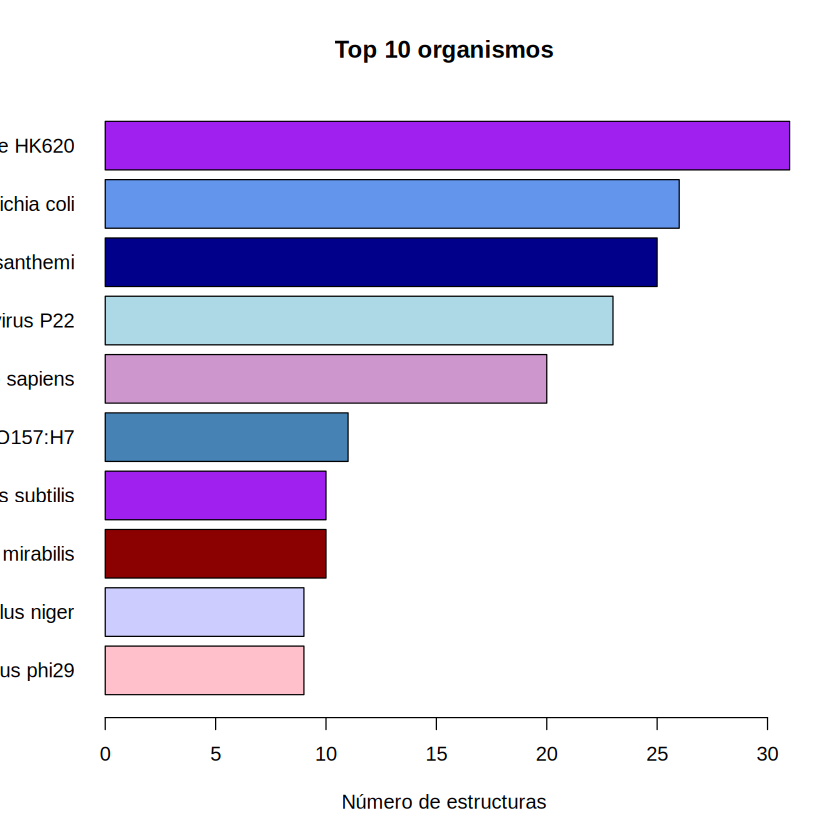

In [ ]:
#lo anterior lo devuelve de forma gráfuica en un barplot
barplot(rev(organismos$estructuras), names.arg = rev(organismos$organismo),
        horiz = TRUE, las = 1, xlab = "Número de estructuras", main = "Top 10 organismos",  col = c("Pink", "#CCCCFF", "#8B0000", "Purple", "steelblue", "plum3", "lightblue", "darkblue", "cornflowerblue", "purple"), cex.names = 1)


## 4. Para las estructuras determinadas mediante cristalografía de rayos X, ¿cómo se distribuyen los valores de resolución? Presenta esta información mediante una gráfica.

In [ ]:
query <- list(
  query = list(
    type = "group",
    logical_operator = "and",
    nodes = list(
      familia,
      list(type = "terminal", service = "text",
           parameters = list(attribute = "exptl.method",
                             operator = "exact_match",
                             value = "X-RAY DIFFRACTION"))
    )
),
  return_type = "entry",
  request_options = list(
    paginate = list(start = 0, rows = 0),
    facets = list(list(
      name = "Resolucion",
      aggregation_type = "histogram",
      attribute = "rcsb_entry_info.resolution_combined",
      interval = 0.5,
      min_interval_population = 1))))

response <- request(url) |> req_body_json(query) |> req_perform()
data <- resp_body_json(response)

grupos <- data$facets[[1]]$buckets
resolucion <- data.frame(
  inicio = as.numeric(sapply(grupos, function(x) x$label)),
  estructuras = as.numeric(sapply(grupos, function(x) x$population))
)
resolucion <- resolucion[order(resolucion$inicio), ]
resolucion


,inicio,estructuras
,<dbl>,<dbl>
1,0.5,1
2,1.0,45
3,1.5,138
4,2.0,128
5,2.5,30
6,3.0,11
7,3.5,3


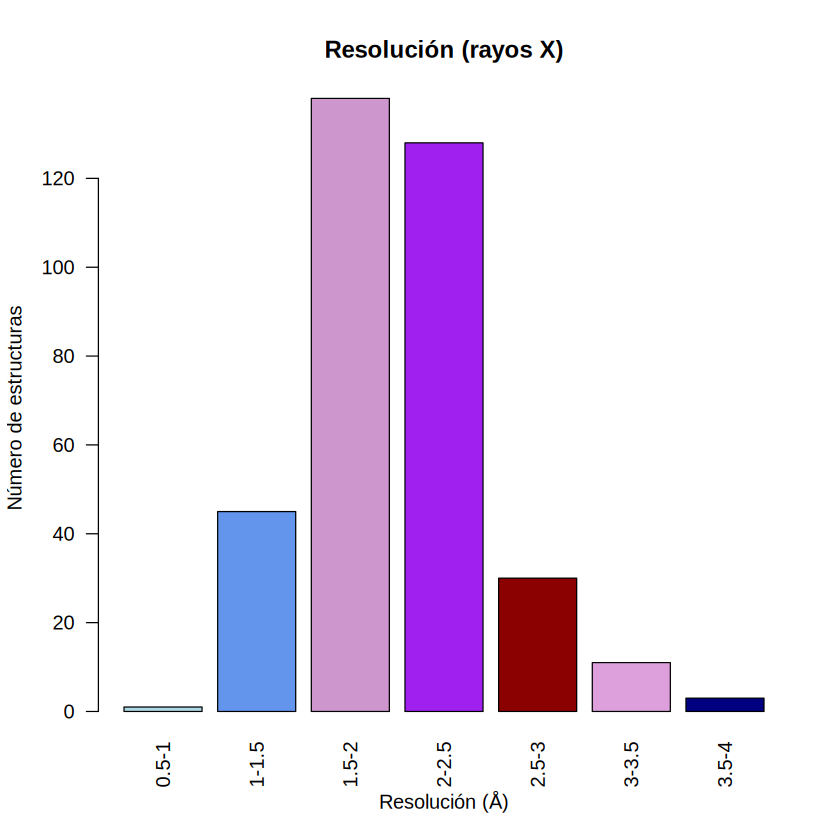

In [ ]:
barplot(resolucion$estructuras, names.arg = paste0(resolucion$inicio, "-", resolucion$inicio + 0.5), las = 2, xlab = "Resolución (Å)", ylab = "Número de estructuras",
main = "Resolución (rayos X)", col = c("lightblue", "cornflowerblue", "plum3", "purple", "darkred", "plum", "navy"))

### 5. ¿Cómo ha cambiado a lo largo del tiempo el número de estructuras depositadas? Construye una línea de tiempo utilizando la fecha de depósito.

In [ ]:
#Se realiza algo similar al hecho en el primer paso:
#Se crea un query como lista, donde incluimos a la familia con la opcion full text
#devolviendo todos los resultados que encuentre
query <- list(
  query = familia,
  return_type = "entry",
  request_options = list(return_all_hits = TRUE))

#Mandamos la peticion, convertimos las listas a json y mandamos la peticion
response <- request(url) |> req_body_json(query) |> req_perform()

#Pasamos de formato json a lista
data <- resp_body_json(response)

#Extrae los idenficiadores de cada proteína
pdb_ids <- sapply(data$result_set, function(x) x$identifier)

#Usamos grapthql para obtener la fecha de deposito de cada id en PDB
url_graphql <- "https://data.rcsb.org/graphql"

#Creamos un vector vacio para guardarlas
fechas <- c()

#Realizamos la fecha de consulta en grupos de 100 en 100 para evitar errores por el limite que acepta graphql
#Este for hace que para cada grupo de 100 entradas, haga la consulta (con paste) y solicite la fecha
#Despues hace la consulta y va guardando las fechas en el vector de fechas para cada ID
for (grupo in split(pdb_ids, ceiling(seq_along(pdb_ids) / 100))) {
  ids_txt <- paste0('"', grupo, '"', collapse = ",")
  q <- paste0("{ entries(entry_ids: [", ids_txt, "]) {
                  rcsb_accession_info { deposit_date } } }")
  resp <- request(url_graphql) |> req_body_json(list(query = q)) |> req_perform()
  d <- resp_body_json(resp)$data$entries
  fechas <- c(fechas, sapply(d, function(e) e$rcsb_accession_info$deposit_date))}

#Luego extreamos el año en el que fueron subidas
#Los contamos con table y cremso un dataframe
tiempo <- as.data.frame(table(anio = as.integer(substr(fechas, 1, 4))))
names(tiempo) <- c("anio", "estructuras")
tiempo$anio <- as.integer(as.character(tiempo$anio))
tiempo


anio,estructuras
<int>,<int>
1993,1
1994,2
1996,6
1997,3
1998,3
1999,14
2000,5
2001,11
2002,21


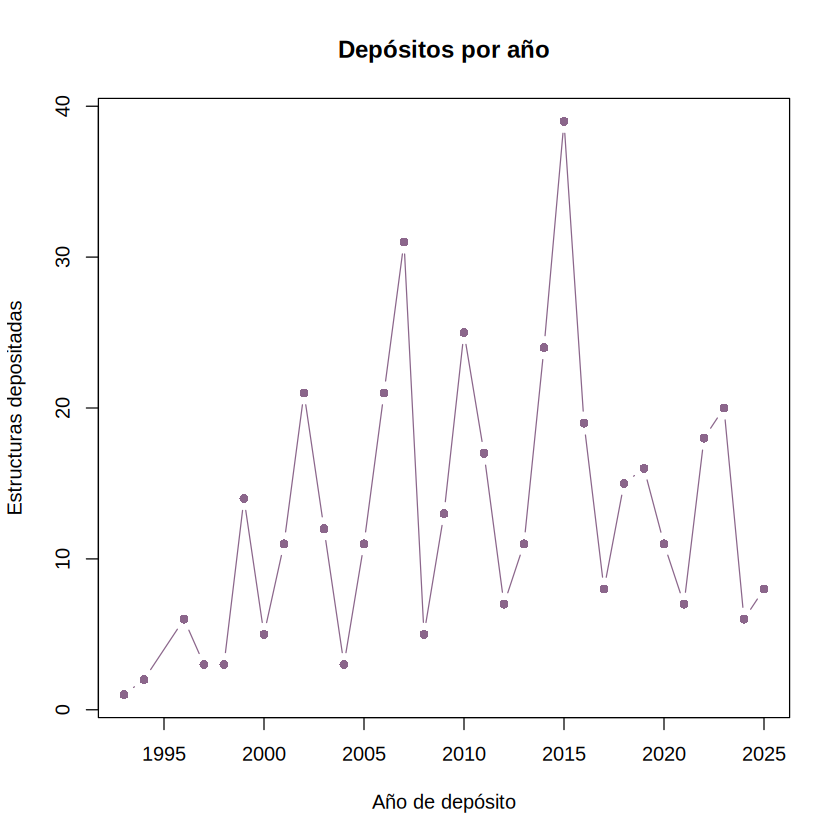

In [ ]:
plot(tiempo$anio, tiempo$estructuras, type = "b", pch = 16,
     xlab = "Año de depósito", ylab = "Estructuras depositadas",
     main = "Depósitos por año", col = "plum4")

Observamos que el deposito de estructuras, comenzó con 1 en 1993, después, de forma general, se fueron descibriendo más estruturas confrome pasaba el tiempo, teniendo su pico de mayores descubrimientos en

### 6. ¿Cómo se distribuyen las longitudes de las proteínas? Indica cómo obtuviste o calculaste la longitud y presenta los resultados gráficamente.

Para la obtención de las longitudes se utilizó el lenguaje de consulta API REST para conseguir los IDs de pectate lyase y después se utilizó el lenguaje de consulta GraphQL a diferencia de API REST, ya que API REST ayuda a conseguir los IDs, mientras que con GraphQL podemos conseguir request de los datos que especifiquemos, en este caso la longitud de las estructuras.

In [ ]:
query <- list( #Realizamos el query para solicitar los IDs de pectate lyase
  query = familia, #Indicamos que queremos aquello que dga pectate lyase
  return_type = "polymer_entity", #Obtendremos los IDs en el formato [pdb_id]_[entity_id]
  request_options = list(return_all_hits = TRUE) #Queremos todos los resultados
)

response <- request(url) |> req_body_json(query) |> req_perform() #Realizamos el request en el PDB Search API de RCSB
data <- resp_body_json(response) #Convertimos los resultados del request a una lista de R

ids_entidad <- sapply(data$result_set, function(x) x$identifier) #Guardamos los IDs en un vector

url_graphql <- "https://data.rcsb.org/graphql" #Utilizaremos GraphQL
longitudes <- c() #Creamos una lista vacía para guardar las longitudes

for (grupo in split(ids_entidad, ceiling(seq_along(ids_entidad) / 100))) { #Creamos grupos de 100 en 100 de los IDs para que no colapse el request
  ids_txt <- paste0('"', grupo, '"', collapse = ",") #Convertimos los IDs en una cadena estando entre comillas y separados por coma; por grupo
  q <- paste0("{ polymer_entities(entity_ids: [", ids_txt, "]) {
                  entity_poly { rcsb_sample_sequence_length } } }") #Creamos el request para GrapQL pidiendo la secuencia de aminacidos por ID
  resp <- request(url_graphql) |> req_body_json(list(query = q)) |> req_perform() #Realizamos el request de GrapQL
  d <- resp_body_json(resp)$data$polymer_entities #Convertimos los resultados del request a una lista de R
  longitudes <- c(longitudes, sapply(d, function(e) e$entity_poly$rcsb_sample_sequence_length)) #Obtenemos las longitudes de cada ID
}

summary(longitudes) #Mostramos las estadísticas de las longitudes


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   18.0   242.0   373.0   445.7   588.5  3250.0 

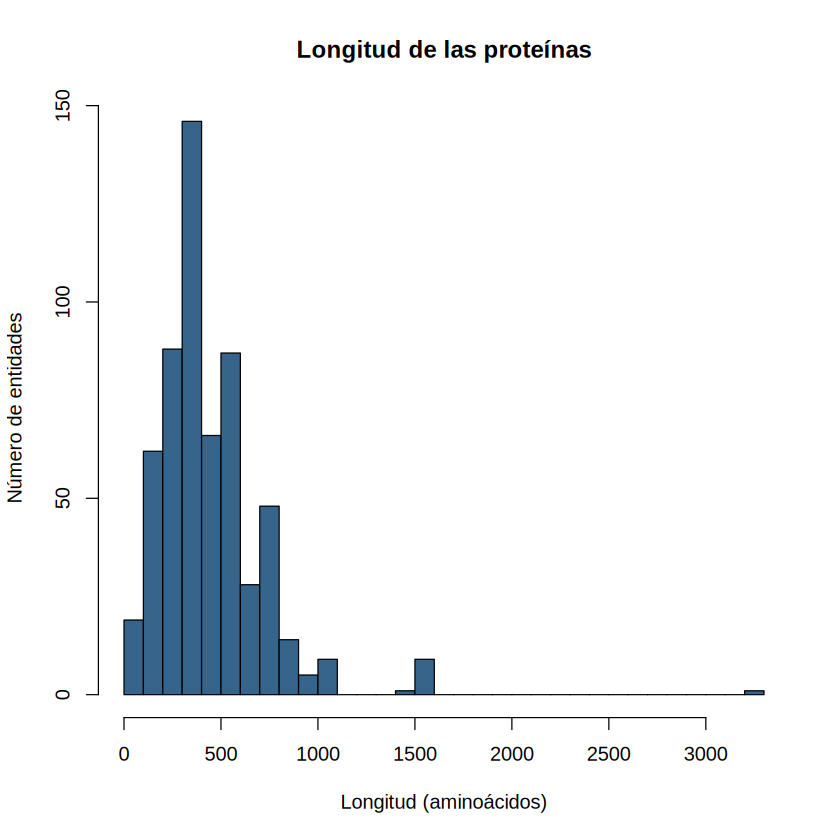

In [ ]:
hist(longitudes, breaks = 30, xlab = "Longitud (aminoácidos)",
     ylab = "Número de entidades", main = "Longitud de las proteínas", col = "steelblue4") #Graficamos las longitudes con un histograma

### 7. ¿Cuáles son los cinco ligandos más frecuentes asociados a las estructuras recuperadas? Presenta sus nombres o identificadores y sus frecuencias.

In [ ]:
query <- list( #Realizamos el query para solicitar los IDs de pectate lyase
  query = familia, #Indicamos que queremos aquello que dga pectate lyase
  return_type = "entry", #Obtendremos los IDs en el formato [pdb_id]
  request_options = list(return_all_hits = TRUE) #Queremos todos los resultados
)

response <- request(url) |> req_body_json(query) |> req_perform() #Realizamos el request en el PDB Search API de RCSB
data <- resp_body_json(response) #Convertimos los resultados del request a una lista de R

pdb_ids <- sapply(data$result_set, function(x) x$identifier) #Guardamos los IDs en un vector

ligandos <- c() # #Creamos una lista vacía para guardar los ligandos

for (grupo in split(pdb_ids, ceiling(seq_along(pdb_ids) / 100))) { #Creamos grupos de 100 en 100 de los IDs para que no colapse el request
  ids_txt <- paste0('"', grupo, '"', collapse = ",") #Convertimos los IDs en una cadena estando entre comillas y separados por coma; por grupo
  q <- paste0("{ entries(entry_ids: [", ids_txt, "]) {
                  nonpolymer_entities { pdbx_entity_nonpoly { comp_id } } } }") #Creamos el request para GrapQL pidiendo las moléculas distintas al polímero incluyendo los ligandos
  resp <- request(url_graphql) |> req_body_json(list(query = q)) |> req_perform() #Realizamos el request de GrapQL
  d <- resp_body_json(resp)$data$entries #Convertimos los resultados del request a una lista de R
  for (e in d) { #Creamos un for para obtener todos los ligandos de cada estructura
    ids_lig <- unique(sapply(e$nonpolymer_entities, function(n) n$pdbx_entity_nonpoly$comp_id)) #Se guardaron cada una de los ligandos de cada estructura
    ligandos <- c(ligandos, unlist(ids_lig)) #Guardamos los ligandos en el vector vacío
  }
}

head(sort(table(ligandos), decreasing = TRUE), 5) #Conseguimos los top 5 ligandos


ligandos
 CA GOL  NA SO4 TRS 
 82  44  44  37  30 

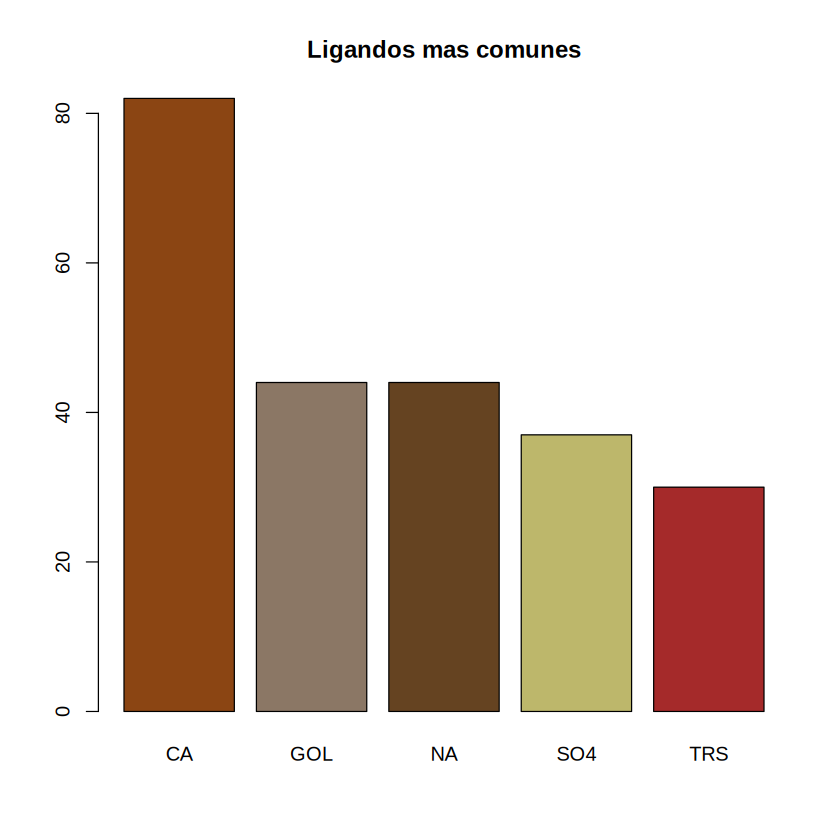

In [ ]:
barplot(head(sort(table(ligandos), decreasing = TRUE), 5), col = c("#8B4513", "peachpuff4", "#654321", "darkkhaki", "brown"), main = "Ligandos mas comunes") #Graficamos los top 5 ligandos

## Parte 3. Exploración estructural

Selecciona al menos una estructura representativa de tu familia y explórala utilizando Mol*, PyMOL o ChimeraX. Incluye una imagen de la estructura y señala, cuando sea posible, elementos de estructura secundaria, la organización general del plegamiento y algún ligando asociado si está presente en el registro.
Acompaña la imagen con el identificador PDB y una breve descripción de lo que estás mostrando.

$$
$$

Se utilizó el programa de Mol* dada su similitud con el visualizador de PDB. Para esto, se utilizó la proteína de las pectato liasas propocionada en durante clase:

- Pectate lyase B from Verticillium dahliae (7BBV)

- ID: pdb_00007bbv

- Displnible en: https://www.rcsb.org/structure/7BBV

Para su visualización, se ingresó al visualizador de Mol* desde el anlace: https://molstar.org/viewer/. Posteriormente, se ingresó el ID de PDB y se visualizó la proteína.


**Estructura**

![](https://i.postimg.cc/kGBF8SCw/Screenshot-from-2026-11-13-22-55-21.png)

**Elementos de la estructura secundaria y Organización general del plegamiento**

![](https://i.postimg.cc/PfCwWZ0p/Whats-App-Image-2026-11-13-at-11-27-35-PM.jpg)

- Es una proteína conformada por 7 vueltas de hélice bethas paralelas, generan una estructura en forma de cilindro hueco




**Sitio Activo**

La Arginina 208 es la base catalítica en pectato lyasa, le arranca un protón al C5 del pectato (el sustrato), esto lo desestabiliza por lo cual forma un doble enlace entre C4 y C5, lo que deja a un oxígeno fuera, es ahí donde entra $H_2O$ y le dona un protón, el agua queda incompleta (como un $OH^{-}$), ahí agarra el proton que arginina había robado y se lo queda.

![](https://i.postimg.cc/9fTJLKDP/Whats-App-Image-2026-11-13-at-11-56-13-PM-(1).jpg)

El pectato queda cortado en dos pedazos y tanto el agua como la arginina vuelven a quedar exactamente como al principio

**Sitio de Unión al Cofactor $Ca^{2+}$**

En el subsitio +1, estarán situados los dos iones de Calcio $Ca^{2+}$, sostenidos por Ácido Glutámico (E) y Aspártico (D), y las Lisinas (K) 175 y 147 tienen cargas positivas, lo que genera un enterono electropositivo que interactuará con con el grupo carboxilato del pectato $-COO^{-}$  que está en C6, vecino del C5,  los iones de Calcio y Lisina interacturaán con los Oxígenos de este grupo neutralizando su carga . Al estar el C6 unido directamente al C5, esta interacción atrae la densidad electrónica hacia el C6 y debilita la unión del protón en el C5, facilitando que Arg208,  rompa del enlace del pectato,

![](https://i.postimg.cc/8cyHFVYg/Whats-App-Image-2026-11-13-at-11-57-32-PM.jpg)

![](https://i.postimg.cc/brYgNv3g/Whats-App-Image-2026-11-13-at-11-56-51-PM.jpg)

**Hendidura de Unión**

La cadena de pectato se acomoda a lo largo de la hendidura ocupando tanto el subsitio -1 como el subsitio +1.

En el subsitio +1 se acomoda el residuo de azúcar blanco del ataque (donde interactúan los iones $Ca^{2+}$ y los aminoácidos E, D y K en su C6, y la Arg208 en su C5), mientras que en el subsitio -1 se sitúa el residuo de azúcar vecino (el que sale y se va). El corte o ruptura ocurre exactamente en el enlace glucosídico entre los subsitios +1 y -1.

![]()

## Parte 4. Interpretación de los resultados

• A partir de tus resultados, ¿qué puedes decir sobre la representación de tu familia en el PDB?

Las pectato liasas están representadas por 413 estructuras dentro de PDB, estando concentradas en pocos organismos modelo, esto debido a que los 10 principales acumulan  cerca 42% de las entradas, lo que puede reflejar cierto sesgo refleja un sesgo. Su depósito ha sido irregular desde 1993, aunque podemos observar de forma general un aumento hasta 2015 y posteriormetne un decremento. Además, la presencia de fagos y otros organismos sin pectato liasas canónicas indica que la búsqueda también recupera proteínas con similar mismo plegamiento, por lo que que es una representacion meno estricta

• ¿Qué observaciones te parecen más interesantes sobre los organismos, los métodos experimentales o la distribución temporal de las estructuras?

- Organismos: Predominan los virus bacteriófagos (como Enterobacteria phage HK620  y Lederbergvirus ) junto con bacterias (E. coli, Dickeya chrysanthemi),también está como representate de eucariotas Homo sapiens. Esto quizás podría reflejar un sesgo a sistemas fáciles de estudiar y cristalizar, o de alto interés en mecanismos de infección.  

- Métodos experimentales: La difracción de rayos X (X-ray diffraction) domina con más de 350 estructuras, frente a unas 50 por criomicroscopía electrónic y menos de 10 por Solution NMR. Esto puede deberse a que la estructura de la pectato liasa quizás y es más fácil de capturar por cristalografía/difracción de rayos X.  

- Distribución temporal: Los depósitos comienzan de en los años 90 pero hay una tendenciaalrededor de 2007 con el mayor peak en 2015, después los depósitos bajan por año


• ¿Qué limitaciones tiene este análisis? Considera, por ejemplo, que el número de estructuras depositadas no necesariamente representa la diversidad real de la familia en la naturaleza.

La estructura que se analiza no contiene el ligando ni la estructura de la proteína en su conformación activa, por lo que si bien podemos ver las interacciones de las moléculas de agua con aminoácidos importantes como la R208 o interacciones entre el ion de calcio $Ca^{2+}$ con los aminoácidos D; sería necesario ver como esas interacciones cambian en el estado activo y si cambiaron de lugar; además ayudaría mucho poder observar como es que el substrato se coloca sobre los subsitios de la pectate lyase. Sin embargo, este procedimiento probablemente sería imposible de ver experimentalmente y se requerirían simulaciones como son aquellas realizadas por BioEmu que se mostró en las clases de Dinámica molecular que podía crear estructuras en la transición de los estados conformacionales.